# chip_11m_testjj16x_pads — the compact trilayer junction cell `JX_500` on its probe-pad pair, on the Quantcore PDK

## 1 · What the chip is

**Source:** `components/python/chip_11m_TestJJ16x_pads.py` (`create_testPad(size, secondFinger)`, writes
`chip_11m_jnc<size>_<secondFinger>.gds` holding one cell `JX_500`; `__main__` calls `create_testPad(2.5, 0.6)`),
Quantcore internal. Spec: `docs/designs/legacy/chip_11m_testjj16x_pads.md`.

Not a full chip but the unit cell of a junction test array, drawn "in-house, without the junction_creator": one
HSQ-spacer trilayer junction in a 12 × 12 µm exposure window — a straight finger on 2/0 (0.2·size = 0.5 µm, no bias),
a bent finger on 4/0 (0.6 µm), two 0.2 µm HSQ boxes with a 45 nm overlap onto the straight finger, and a triangular
notch cut from each finger window where its lead leaves the window. `chip_11f_JJplacer.py` places this cell (built
with size 1.0, a 0.2 µm finger) at coordinates from an external CSV. The script defines two 500 × 400 µm probe pads
and a 600 × 1000 µm window but never inserts them (the two lines are commented out); the script declares the
gradient layers 52/53/54 but draws no spacer gradient.

| | the rebuild keeps (source-faithful) | the Quantcore PDK changes |
|---|---|---|
| junction, pads | the junction cell (`TrilayerJunctionCompact`, the port of `JX_500`) in a `ProbePadPair` (the commented-out pads, legacy sizes: `middle_height` 200 µm, the pads end 100 µm from the junction; upper pad on 1/0, lower in the 3/0 second metal) | the junction valued on the PDK process: 0.5 × 0.6 µm → 45 kΩ, exactly the PDK nominal (no `pdk_rn`) |
| bond pads | — (probe pads belong to the test structures; no bond pads or launchers) | the pad rule (`frame.pad_edge`, 100 µm) has nothing to move (step 4) |
| cheese | — (the source has none) | the **PDK band** (3 rows of 5 µm squares, 20 µm gaps, around the 3/0 keep-outs; `cheese: "auto"`), drawn by the build and kept by the fab mask |
| placement | the bare cell at the legacy origin | at the die centre (step 7: already centred) |
| frame | — (the source writes the bare cell, no die) | the PDK die frame and device ID `CHIP11M` (open: confirm, or say which chip it belongs to) |
| FEM | — | no sim groups: nothing to excite (steps 11–12 say so) |

**Reproduced exactly** (step 15): the junction cell on every junction layer (XOR-clean vs the legacy `JX_500`, also `tests/test_keepout.py::test_probe_pad_pair_matches_legacy`).

### Changes after design review (2026-11-03)

- **#1 junction values — PDK trilayer rule** (Nb, Δ = 1.4 meV, I_c·R_n = πΔ/2e = 2.20 mV, R_n 40–50 kΩ for the
  qubits): the drawn legacy junction fingers are kept and valued on the PDK
  process (R_n·A 13.5 kΩ·µm², C_J 50 fF/µm², both assumed by the PDK; 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH; R_n ∝
  1/area). The earlier assumed J_c = 1 µA/µm² is gone. Values in step 10.

### PDK conformance pass (notebooks-legacy, 2026-11-18)

- **Pads:** none. The probe pads belong to the test structures and are not bond pads or launchers, so the pad rule
  (`frame.pad_edge`, 100 µm) has nothing to move; `C.pads_md(d)` confirms it (step 7).
- **Centring:** `L.center_circuit` (each axis only if > 50 µm off): shift (0, 0): the cell sits at the die centre.
- **Cheese:** the source has none, so the PDK band applies (`cheese: "auto"`), drawn by the build and kept by the
  fab mask.
- **Junctions:** the legacy fingers, valued on the PDK process; `pdk_rn` flags a junction outside 40–50 kΩ (only
  cells that carry lumped junction values are checked), never retuned.
- **No FEM groups** (nothing to excite): steps 11 and 12 say so.
- Educative layout: one step per stage; the steps that do not apply to a test chip (pads, routes, FEM) say so.

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks (`_legacy_b`, `LB`, adds the legacy cells of the later chips). `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
import _legacy_b as LB                               # Connector Pad 2, holes, labels, xjc scripts, junction XOR

from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "chip_11m_testjj16x_pads", Path("examples/designs/legacy")

The PDK facts this rebuild uses, read from `get_pdk()` (nothing below is typed in by hand). The rules that
change a legacy chip are the **pad rule** (step 4), the **junction rule** (step 5), the **3/0 keep-out**
and the **cheese rule** (drawn by the build, step 14) and the centring of the content (step 7).

In [3]:
CHEESE_NOTE = 'PDK band (auto) — the source has no cheese of its own'
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: PDK band (auto) — the source has no cheese of its own |

### The source's numbers

`create_testPad(2.5, 0.6)`'s numbers (µm): the size, the straight finger 0.2·size and the 12 µm window.

In [4]:
# chip_11m_TestJJ16x_pads.py, legacy frame (µm)
SIZE, SECOND = 2.5, 0.6                              # __main__: create_testPad(2.5, 0.6)
FINGER = 0.2 * SIZE                                  # finger_width = 0.2 * size (no bias)
WINDOW = 12.0                                        # junction_width + 1

## 3 · The die and the frame

`Designer(ID, box=...)` starts an empty 7.5 × 7.5 mm die (the PDK standard die). The PDK frame is drawn on every
build: four L-shaped dicing markers (1000/0), the 3 × 3 alignment grids (1001/0), the chip boundary (100/0) and the
device ID `CHIP11M` (`name_chip`; optional: the frame places it where it is free). The chip parameter
`cheese` is left at `"auto"`: the source has no cheese, so the build draws the PDK band (visible from step 5 on).

(0.0, 0.0, 7500.0, 7500.0) quantcore_nb_sapphire_v1


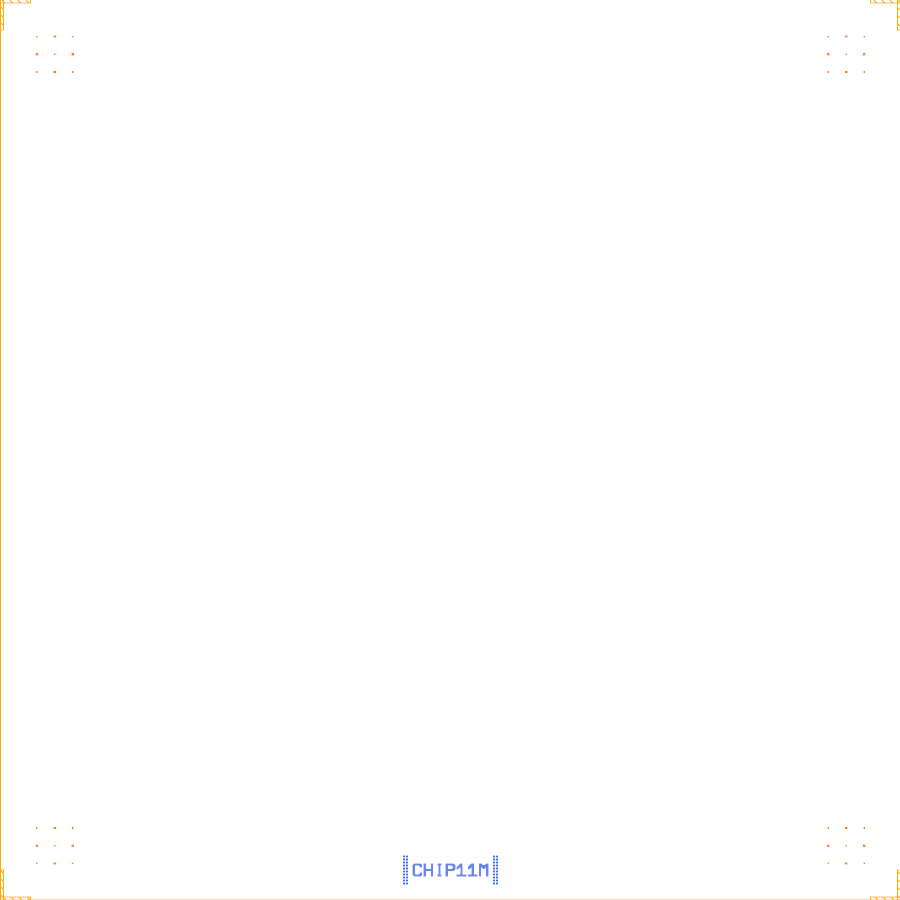

WindowsPath('build/legacy_steps/chip_11m_testjj16x_pads_1_frame.png')

In [5]:
d = Designer(ID, box=(0, 0, L.W, L.H), chip={"name_chip": "CHIP11M"}, live=LIVE)   # cheese "auto"
print(d.design.chip.box, d.design.pdk)
L.step_snapshot(d, "1_frame")

## 4 · Pads (PDK pad rule): does not apply

The PDK pad rule puts every bond pad / launcher with its outer etch `frame.pad_edge` = 100 µm from the die edge
(`edge="auto"`). This chip has none: its probe pads are part of the test structures (placed in step 5, at the
source's positions, all well inside the design area). Step 7 lists the chip's bond pads with `C.pads_md(d)`: none.

## 5 · Components: the test structures

One `ProbePadPair` (`junction_type="Trilayer Junction Compact"`, the `JX_500` junction in the pair's centre cut-out)
with the `__main__` parameters, centred on the junction (origin = the junction site), so it is placed at the legacy
(0, 0). Junction values from the drawn area (`L.jj`, PDK junction rule).

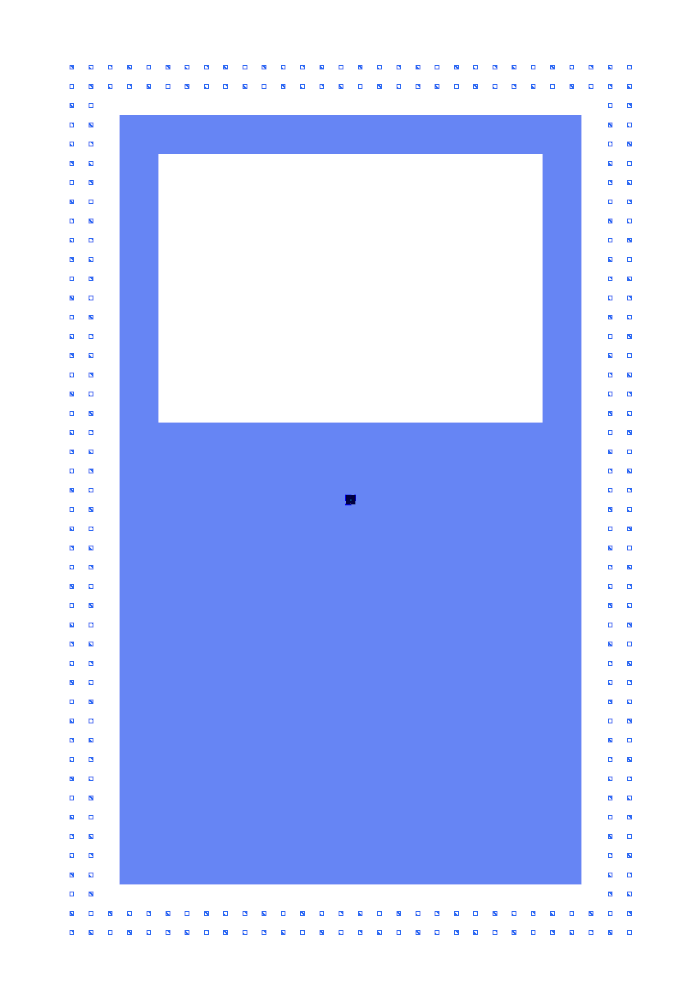

WindowsPath('build/legacy_steps/chip_11m_testjj16x_pads_2_pair.png')

In [6]:
jx = d.add("JX", "ProbePadPair", **L.place(0, 0), junction_type="Trilayer Junction Compact",
           junction_params={"finger_width": FINGER, "second_finger_width": SECOND}, junction=L.jj(FINGER, SECOND))
L.step_snapshot(d, "2_pair", box=(3300, 3100, 4200, 4400), size=(700, 1000), width=280)

## 6 · Routes: does not apply

No routes: the test structures are probed directly (needles or wire bonds on their own pads), nothing is wired on
chip.

## 7 · Cheese, pads check and centring

**Cheese.** The source has no cheese, so the build draws the **PDK band** (`cheese: "auto"`): 3 rows of 5 µm squares
with 20 µm gaps around the 3/0 keep-outs, at least 4 µm from 3/0, never over empty ground (visible in the snapshots
as the dotted rings around each structure).

**Centring (PDK placement rule).** `L.center_circuit` measures the circuit (instances, free text labels left out) and
shifts the design so it sits in the middle of the die, each axis only if it is more than 50 µm off. Then the design
is saved, and `C.pads_md(d)` checks the pad rule (no bond pads).

centring shift (µm): (0.0, 0.0) | <Designer chip_11m_testjj16x_pads: 1 instances, 0 routes, live=False> → examples\designs\legacy\chip_11m_testjj16x_pads.json


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

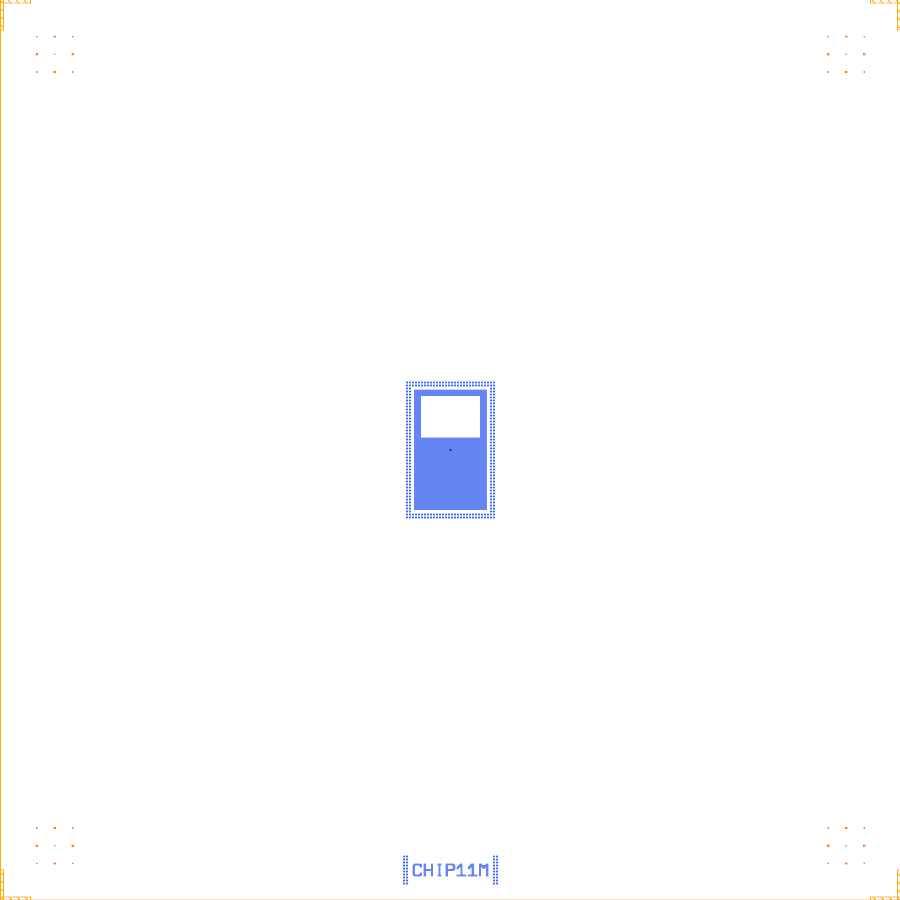

WindowsPath('build/legacy_steps/chip_11m_testjj16x_pads_3_centred.png')

In [7]:
SHIFT = L.center_circuit(d)
DESIGN = d.save(OUT / f"{ID}.json")
print("centring shift (µm):", SHIFT, "|", d, "→", DESIGN)
display(Markdown(C.pads_md(d)))
L.step_snapshot(d, "3_centred")

## 8 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip, a route looping over itself or running over a component) must be fixed; **warnings** are
reported for a person to judge (a dangling open end, two cells' bounding boxes touching); **PDK design warnings**
(`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside the PDK margins — they are never retuned for, only
listed. `C.pdk_report(d)` summarises the PDK checks: cheese source, content centring (free text labels left out),
junction types and the design warnings.

Expected (this run): **DRC clean** — zero errors, no warnings (`ProbePadPair` is a DC pad structure with no ports; the
junction sits in its cut-out between the two pads), no PDK design warnings: the 0.5 × 0.6 µm junction is exactly
the PDK nominal 45 kΩ. `pdk_report`: cheese "PDK band", content centre (+0, +0) µm, junction types `Trilayer
Junction Compact` × 1. The device ID `CHIP11M` sits at the bottom edge centre.

In [8]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

DRC clean


| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Trilayer Junction Compact × 1 |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

The `ProbePadPair` carries the junction's lumped values (checked by `pdk_rn`), but it has no LOM model of its own and the
pads are not circuit elements, so the netlist is empty (only ground).

In [9]:
lb = d.lom()
C.show_netlist(lb)
print(C.lom_summary(lb))

**1 nodes · 0 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |

| branch | type | nodes | estimate |
|---|---|---|---|

**Unconnected ports:** none

{'nodes': 0, 'branches': 0, 'controls': 0, 'unconnected': 0}


## 10 · LOM simulation: does not apply — the junction table instead

A junction cell has no circuit to simulate (the pads are not circuit elements); the values follow from the drawn
finger widths (area = straight × bent finger, R_n = (R_n·A) / area, L_J from Ambegaokar–Baratoff, `circuit.bridges`)
on the PDK junction rule. The second row is the size-1.0 variant that chip_11f places.

In [10]:
display(Markdown(L.junction_table([
    ("JX (`create_testPad(2.5, 0.6)`, this design)", FINGER, SECOND, 1),
    ("JX_500 placed by chip_11f (`create_testPad(1.0, 0.6)`)", 0.2 * 1.0, SECOND, 1),
])))

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK).

Drawn junctions (legacy fingers) on the PDK process:

| junction | fingers (µm) | n | area (µm²) | R_n (kΩ) | I_c (nA) | L_J (nH) | C_J (fF) |
|---|---|---|---|---|---|---|---|
| JX (`create_testPad(2.5, 0.6)`, this design) | 0.5 × 0.6 | 1 | 0.3000 | 45.00 | 48.9 | 6.734 | 15.00 |
| JX_500 placed by chip_11f (`create_testPad(1.0, 0.6)`) | 0.2 × 0.6 | 1 | 0.1200 | 112.50 | 19.5 | 16.836 | 6.00 |

**Reading the numbers** (this run): this design's junction (`create_testPad(2.5, 0.6)`: 0.5 × 0.6 µm) is 45.0 kΩ, L_J
6.73 nH, C_J 15 fF — the PDK nominal; the size-1.0 variant that chip_11f places (0.2 × 0.6 µm) is 112.5 kΩ.

## 11 · FEM: send the job — does not apply

A FEM job needs a sim group: a qubit / resonator cut-out with a port to excite. This chip has none (probe
structures only), so `C.export_sims(DESIGN)` exports nothing and `L.fem_send` says so. The cell stays so the
notebook has the same shape as the others (and `RUN_FEM` would have nothing to solve).

In [11]:
RUN_FEM = False                       # nothing to solve: the chip has no sim groups
jobs = C.export_sims(DESIGN)
display(Markdown(C.jobs_md(jobs) if jobs else "*no sim groups — nothing to export*"))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

*no sim groups — nothing to export*

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

No FEM jobs: this chip has no sim groups (nothing to excite).

## 12 · Bring the results back — does not apply

No jobs, so no results to bring back (`L.fem_bring_back` says "No FEM jobs."). On a test chip the "results" are the
probe-station R_n values, compared with the junction table of step 10.

In [12]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM jobs.

## 13 · Iterate: change one property and rebuild

This chip's junction is exactly the PDK nominal (0.5 × 0.6 µm, 45 kΩ). A copy builds the size-1.0 variant that
chip_11f places (0.2 µm straight finger), with its lumped values, and runs the DRC again: a `pdk_rn` warning appears
(112.5 kΩ). The copy is not saved.

In [13]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved design
jp = dict(d2.data["instances"]["JX"]["params"]["junction_params"])
d2["JX"].set(junction_params=jp | {"finger_width": 0.2}, junction=L.jj(0.2, SECOND))
pdk_warnings = lambda rep: [i.message for i in rep.issues if i.rule.startswith("pdk_")]
print("PDK design warnings:", pdk_warnings(drc), "→", pdk_warnings(d2.drc()))

PDK design warnings: [] → ['JX: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH)']


**Result** (this run): the size-1.0 junction (0.2 µm straight finger) raises a `pdk_rn` warning (112.5 kΩ, L_J 16.84 nH)
in the copy's DRC: none before, one after.

## 14 · Build and export

The design is saved as JSON (`DESIGN`, step 7): it is the source of truth — the layout, the netlist, the
FEM jobs and the mask are all made from it. The **fab mask** (`export_fab`) keeps only the PDK fab layers
(1/0 etch, 2/0 + 4/0 junction fingers, 3/0 second-metal keep-out, 50–53/0 spacer, 100/0 boundary, 1000/0 +
1001/0 markers), rounds the corners (radius ∝ each polygon's shortest dimension) and keeps the build's
cheese; every cheese hole of 1/0 is also on 3/0. **Simulation exports** never carry cheese; they drop airbridges
unless asked (`build_simulation(..., airbridges=True)`); the legacy chips have none.

Here: `cheese=True` (the default): the build already carries the PDK band (the source has no cheese), so the mask
keeps it (`cheese_source` "build"), on 1/0 and on 3/0.

The same from a shell:

```
qcc build examples/designs/legacy/chip_11m_testjj16x_pads.json                    # layout → build/chip_11m_testjj16x_pads.oas
qcc mask  examples/designs/legacy/chip_11m_testjj16x_pads.json          # fab mask with the PDK rules
```

In [14]:
display(Markdown(L.fab_md(d)))

Fab mask: `build/chip_11m_testjj16x_pads_fab.oas` · cheese source **build** (328 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 336 |
| 2/0 | JJ_STRAIGHT | 1 |
| 3/0 | M3 | 332 |
| 4/0 | JJ_BENT | 1 |
| 50/0 | HSQ | 2 |
| 51/0 | SPACER_1 | 2 |
| 52/0 | SPACER_2 | 2 |
| 53/0 | SPACER_3 | 2 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

## 15 · Snapshots and comparison with the legacy geometry

Full die (the cell is a dot at the centre); the 12 µm junction window; the finger overlap with the HSQ boxes.

Then the cell drawn by the author's legacy script (run read-only through `tests/legacy_ref`:
`chip_11m_TestJJ16x_pads.create_testPad(2.5, 0.6)` with the author's `JJ_finger` PCells), placed at the legacy (0, 0)
and moved by the centring shift, and the XOR per junction layer against the rebuild (legacy 2/0 →
`1t1_SIS_junction`, 4/0 → `1t1_SIS_junction_2`, HSQ 500/0 → PDK 50/0; slivers ≤ 2 nm ignored). There is no 1/0
geometry to compare.

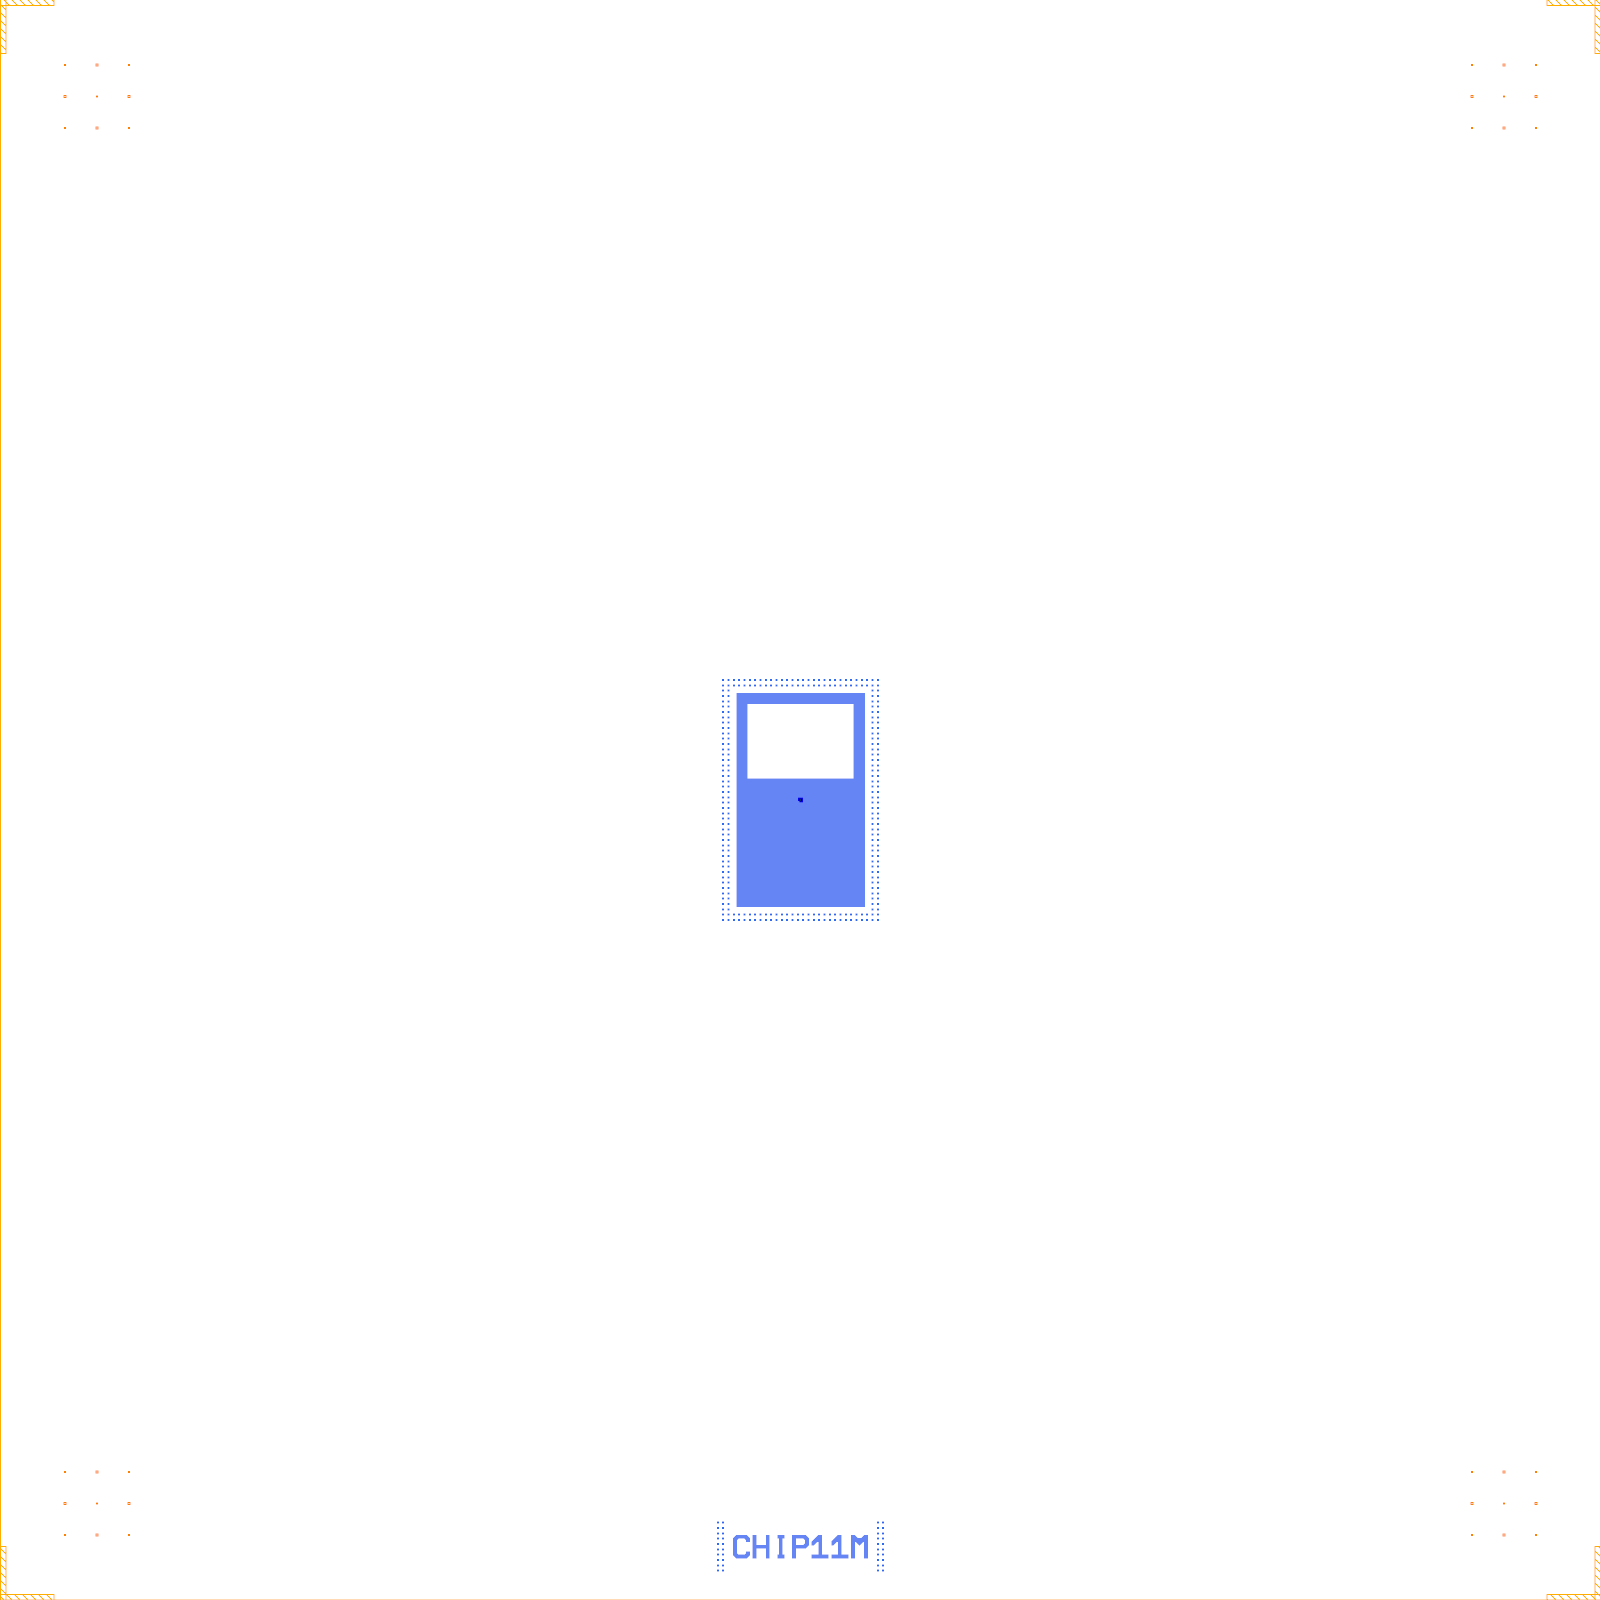

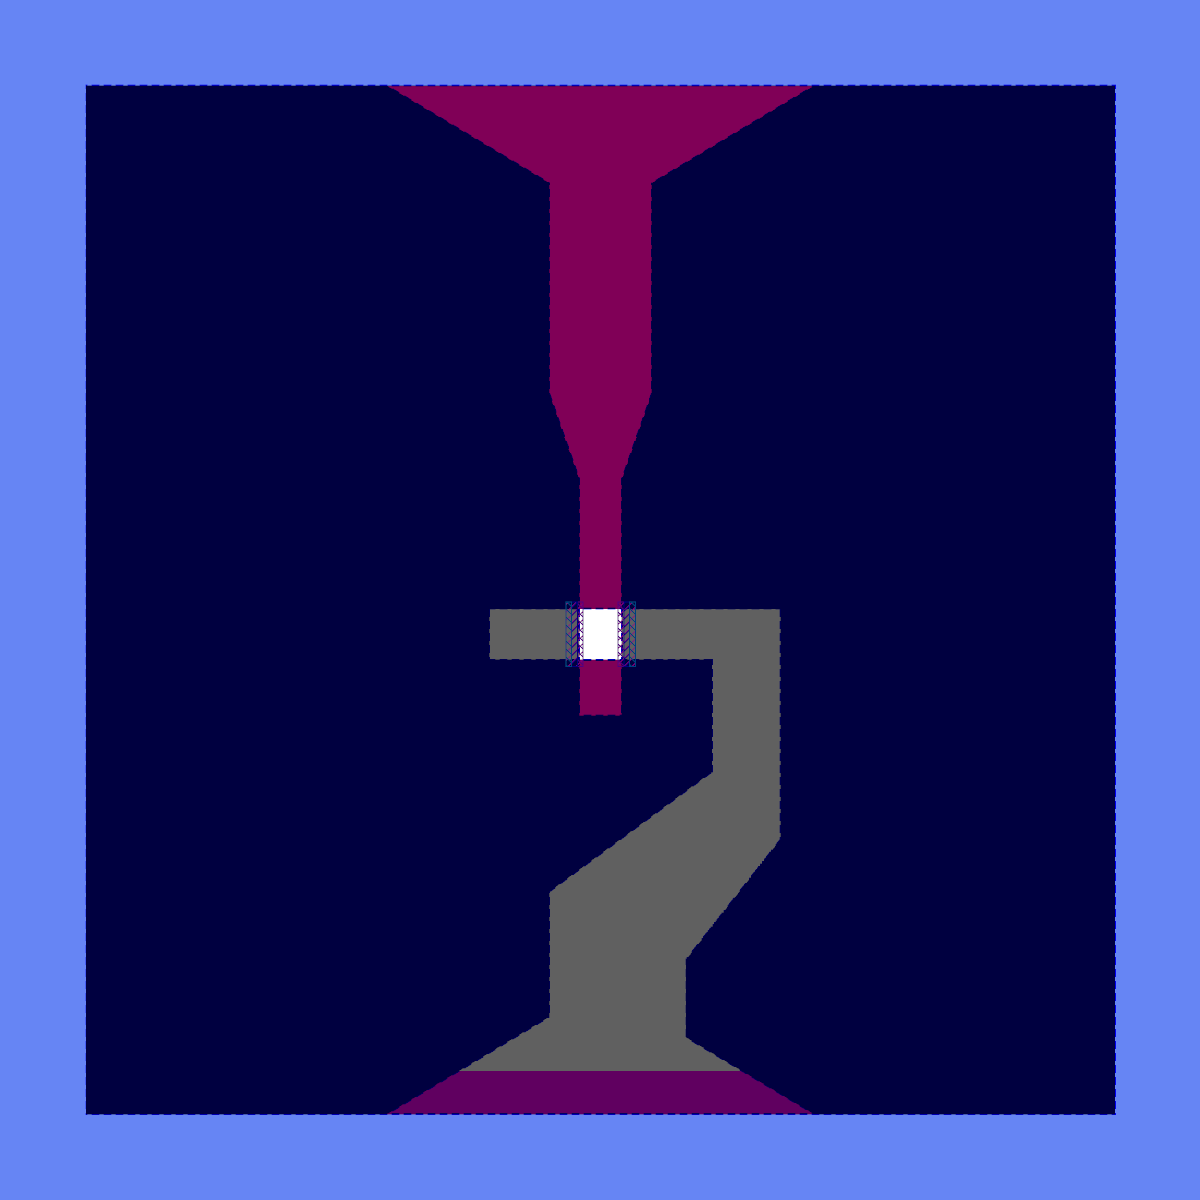

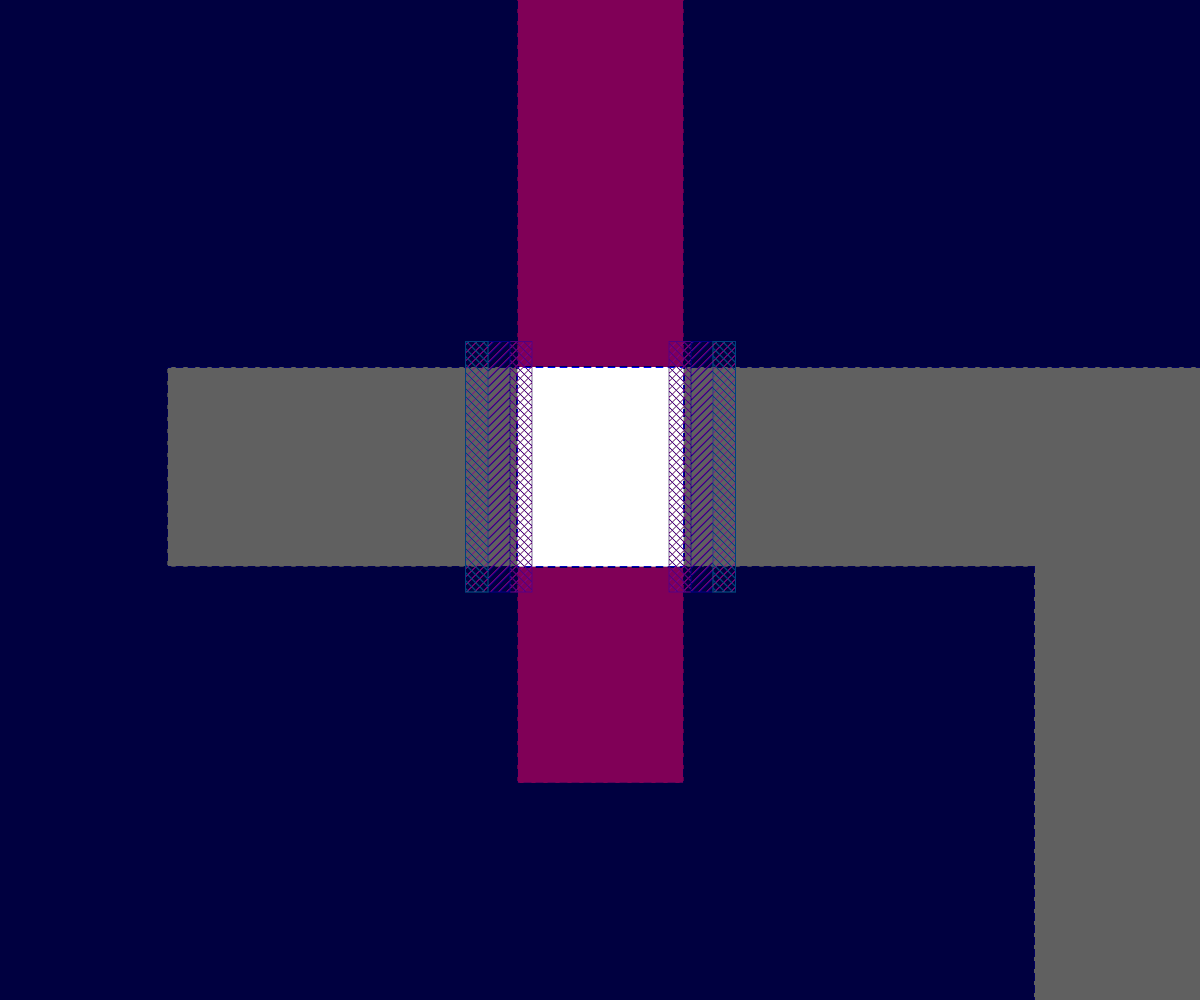

WindowsPath('examples/designs/legacy/chip_11m_testjj16x_pads_overlap.png')

In [15]:
(x0, y0) = L.origin(d, "JX")
C.show_snapshot(d, OUT / f"{ID}.png", box=(0, 0, L.W, L.H))   # die box (the instance-name layer reaches past it)
C.show_snapshot(d, OUT / f"{ID}_jj.png", box=(x0 - 7, y0 - 7, x0 + 7, y0 + 7), size=(1200, 1200), width=360)
C.show_snapshot(d, OUT / f"{ID}_overlap.png", box=(x0 - 1.5, y0 - 2, x0 + 1.5, y0 + 1), size=(1200, 1000), width=360)

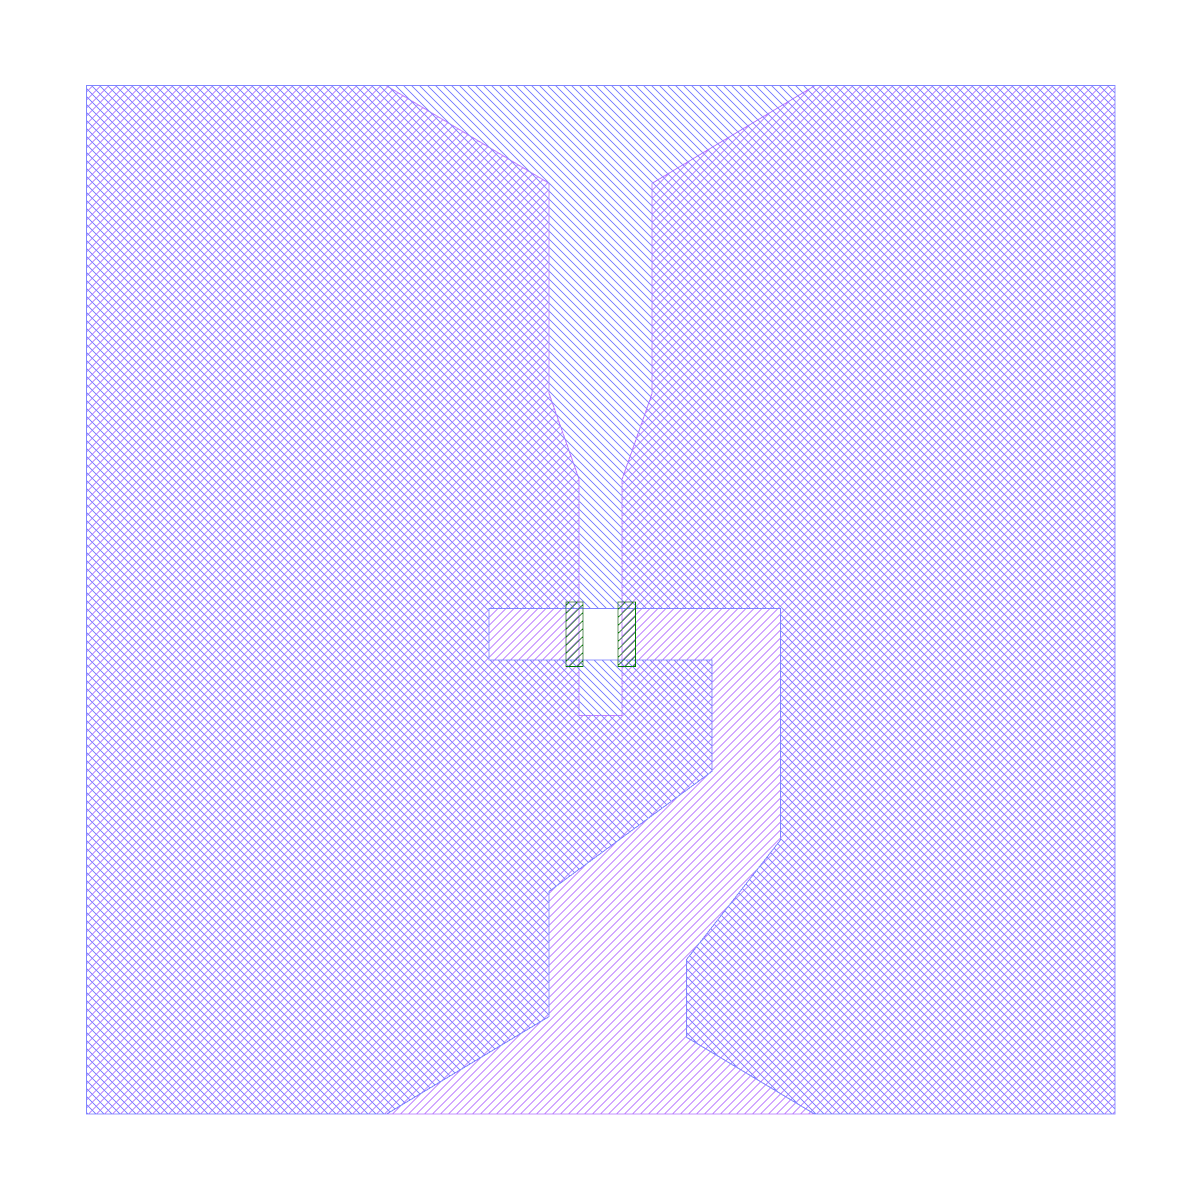

largest junction-layer XOR 0.0000 µm² (('JX', 'straight finger 2/0'))


| instance | layer | legacy (µm²) | rebuilt (µm²) | XOR (µm²) |
|---|---|---|---|---|
| JX | straight finger 2/0 | 135.289 | 135.289 | 0.0000 |
| JX | bent finger 4/0 | 132.442 | 132.442 | 0.0000 |
| JX | HSQ spacer (legacy 500/0 → 50/0) | 0.300 | 0.300 | 0.0000 |

In [16]:
if L.legacy_available():
    ref = LB.legacy_chip(ID)
    cell = L.legacy_script_cell("chip_11m_TestJJ16x_pads.py", "create_testPad", "JX_500", SIZE, SECOND,
                                tmp="build/legacy_b/chip_11m/main")
    ref.cell_from("JX", *cell, 0, 0)
    ref = L.shift_reference(ref, *SHIFT)
    from quantcore_circuits.live.snapshot import snapshot
    snapshot(ref.write(f"build/legacy_b/{ID}_legacy.oas"), OUT / f"{ID}_legacy.png",
             box=(x0 - 7, y0 - 7, x0 + 7, y0 + 7), size=(1200, 1200))
    display(Image(filename=str(OUT / f"{ID}_legacy.png"), width=360))
    table, xor = LB.junction_xor(d, ref)
    print(f"largest junction-layer XOR {max(xor.values()):.4f} µm² ({max(xor, key=xor.get)})")
    display(Markdown(table))
else:
    print("components/ (legacy library) not present: no legacy reference")

## 16 · Summary

- **Matches the source:** the `JX_500` junction cell on every junction layer (XOR 0 µm² against the legacy
  `create_testPad(2.5, 0.6)` output).
- **Cell switch:** the commented-out probe-pad pair is drawn (`ProbePadPair`, legacy sizes).
- **Differs, by the PDK:** the PDK die frame and device ID `CHIP11M` (ID to be confirmed), the PDK cheese band
  (fab cheese source "build", 328 holes). Centring shift (0, 0).
- **Steps that do not apply:** pads, routes, LOM simulation (junction table instead), FEM.
- **Open:** none (0 PDK design warnings: the junction is the PDK nominal).